
🎯 TEST DU MODÈLE AVEC AFFICHAGE

Test avec un chat:


C:\Users\bello\AppData\Local\Temp\ipykernel_8688\659106475.py:55: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\bello\AppData\Local\Temp\ipykernel_8688\659106475.py:55: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


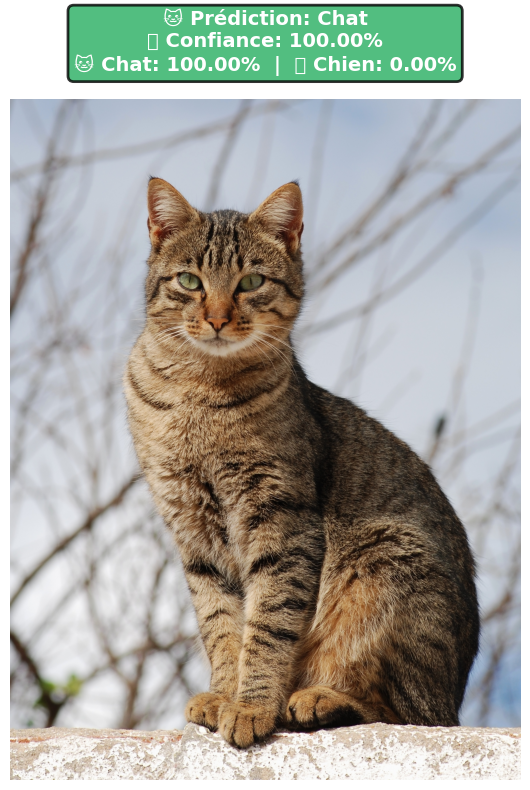

Test avec un chien:


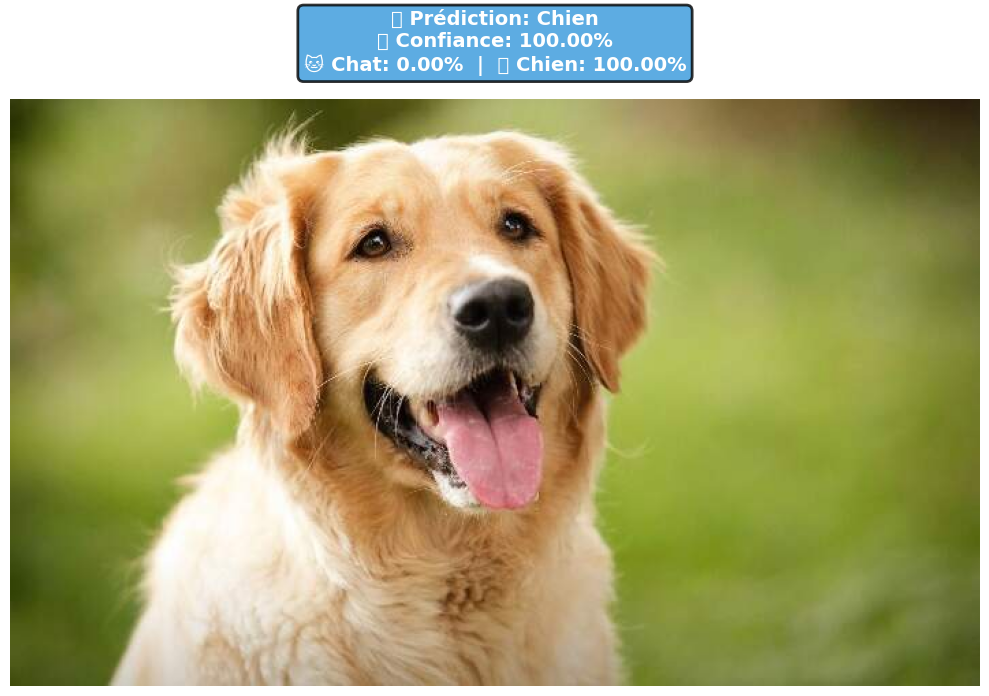

Test avec un autre objet:


C:\Users\bello\AppData\Local\Temp\ipykernel_8688\659106475.py:55: UserWarning: Glyph 10067 (\N{BLACK QUESTION MARK ORNAMENT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


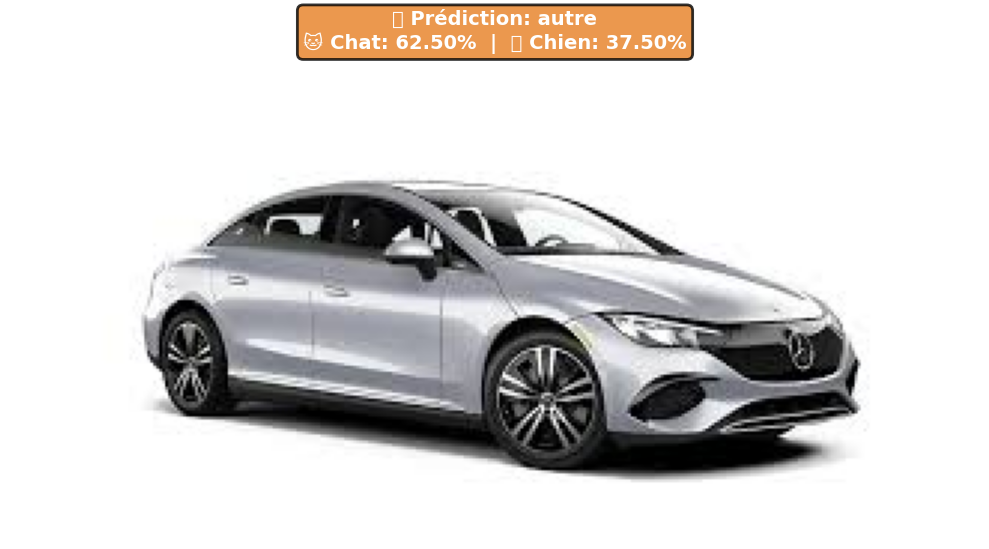

In [3]:
from ultralytics import YOLO
import os
import matplotlib.pyplot as plt
from PIL import Image

def test_image(image_path, model_path='cat_dog_cls/yolo11/weights/best.pt', confidence_threshold=0.85):
    
    if not os.path.exists(image_path):
        print(f"❌ Erreur: L'image '{image_path}' n'existe pas!")
        return None
    
    # Charger le modèle
    model = YOLO(model_path)
    
    # Faire la prédiction
    results = model.predict(image_path, verbose=False)
    
    # Extraire les résultats
    top_class = results[0].probs.top1  # 0 = Cat, 1 = Dog
    confidence = results[0].probs.top1conf.item()
    cat_prob = results[0].probs.data[0].item()
    dog_prob = results[0].probs.data[1].item()
    
    # Décision basée sur le seuil de confiance
    if confidence >= confidence_threshold:
        predicted_class = 'Chat' if top_class == 0 else 'Chien'
        emoji = '🐱' if top_class == 0 else '🐶'
        color = '#27AE60' if top_class == 0 else '#3498DB'
        
        # Pour Chat/Chien: afficher la confiance
        result_text = f'{emoji} Prédiction: {predicted_class}\n'
        result_text += f'📊 Confiance: {confidence*100:.2f}%\n'
        result_text += f'🐱 Chat: {cat_prob*100:.2f}%  |  🐶 Chien: {dog_prob*100:.2f}%'
    else:
        predicted_class = 'autre'
        emoji = '❓'
        color = '#E67E22'
        
        # Pour "autre": NE PAS afficher la confiance, seulement les probabilités
        result_text = f'{emoji} Prédiction: {predicted_class}\n'
        result_text += f'🐱 Chat: {cat_prob*100:.2f}%  |  🐶 Chien: {dog_prob*100:.2f}%'
    

    img = Image.open(image_path)

    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(img)
    ax.axis('off')
    

    ax.set_title(result_text, fontsize=14, fontweight='bold', pad=20,
                bbox=dict(boxstyle='round', facecolor=color, alpha=0.8,
                         edgecolor='black', linewidth=2), color='white')
    
    plt.tight_layout()
    plt.show()
    
    return predicted_class



if __name__ == "__main__":
    
    print("\n🎯 TEST DU MODÈLE AVEC AFFICHAGE\n")
    
    # Test avec un chat
    if os.path.exists('test_cat.jpg'):
        print("Test avec un chat:")
        result = test_image('test_cat.jpg')

    
    # Test avec un chien
    if os.path.exists('test_dog.jpg'):
        print("Test avec un chien:")
        result = test_image('test_dog.jpg')

    
    # Test avec un autre objet
    if os.path.exists('other.jpg'):
        print("Test avec un autre objet:")
        result = test_image('other.jpg')


    
